# CityVision — Preuve de concept : préparation des données et entraînement

**Segmentation sémantique de scènes urbaines (Cityscapes, 9 classes)** : entraînement de la
**baseline** (ResNet50‑UNet) et de la **nouvelle méthode**, Mask2Former puis **EoMT**, dans les
mêmes conditions, puis comparaison.

| Modèle | Rôle | Référence |
|---|---|---|
| ResNet50‑UNet | baseline du projet (classification de chaque pixel) | Ronneberger et al., 2015 ; He et al., 2016 |
| Mask2Former (Swin‑Tiny) | nouvelle méthode, étape intermédiaire | Cheng et al., CVPR 2022, arXiv:2112.01527 |
| **EoMT (ViT‑B, DINOv2)** | **nouvelle méthode retenue** | Kerssies et al., 2025, arXiv:2503.19108 |

**Plan**
1. Configuration et jeu de données
2. Préparation des données
3. Outils communs (métrique, boucle d'entraînement)
4. Baseline : ResNet50‑UNet
5. Nouvelle méthode (1) : Mask2Former
6. Nouvelle méthode (2) : EoMT
7. Résultats et comparaison
8. Conclusion

**Exécution**
- Durée totale sur le GPU du projet (RTX 2000 Ada, 8 Go) : **environ 20 h** (baseline ≈ 5 h,
  Mask2Former ≈ 6 h, EoMT ≈ 10 h).
- Chaque section d'entraînement enregistre son checkpoint et son historique sur disque : le notebook
  peut donc être exécuté en plusieurs fois (un modèle par session, via le dictionnaire `TRAIN`), la
  section 7 utilise ce qui est disponible.
- Les checkpoints de ce notebook sont écrits dans `model_backups/notebook/` et les runs MLflow
  préfixés `NB-` : ils **n'écrasent pas** les modèles de référence (rapport, dashboard déployé).
- Code réutilisé : implémentations Hugging Face Transformers (`Mask2FormerForUniversalSegmentation`,
  `EomtForUniversalSegmentation`) et recette d'entraînement du dépôt officiel EoMT
  (github.com/tue-mps/eomt, licence MIT). Le reste (données, boucles, évaluation) est propre au projet.

## 1. Configuration et jeu de données

### Où trouver le jeu de données

Le jeu de données **n'est pas inclus dans le dépôt** : la licence Cityscapes interdit de le
redistribuer, et il pèse environ 11 Go. Le notebook le lit **sur ce PC**.

- **Source** : Cityscapes, https://www.cityscapes-dataset.com (inscription gratuite pour usage
  non commercial), ou les archives fournies pour le projet (dossiers `P8_Cityscapes_…`).
- **Fichiers nécessaires** :
  - `leftImg8bit_trainvaltest` — les images (2048×1024, PNG) ;
  - `gtFine_trainvaltest` — les annotations fines (fichiers `*_gtFine_labelIds.png`).
- **Où les placer** (chemins utilisés ci‑dessous, relatifs à la racine du projet) :

```
data/cityscapes/
├── P8_Cityscapes_leftImg8bit_trainvaltest/leftImg8bit/{train,val,test}/<ville>/*_leftImg8bit.png
└── P8_Cityscapes_gtFine_trainvaltest/gtFine/{train,val,test}/<ville>/*_gtFine_labelIds.png
```

Pour un autre emplacement, modifier `IMG_ROOT` et `MASK_ROOT` dans la cellule suivante.

In [1]:
import contextlib
import gc
import inspect
import json
import math
import os
import random
import sys
import time
from itertools import islice

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as tv_models
from PIL import Image
from torch.utils.data import DataLoader
from tqdm import tqdm
import transformers

# Sorties lisibles : pas de barres de progression ni de rapports de chargement de transformers
# (les têtes de classification remplacées y apparaissent comme « MISMATCH », c'est voulu)
transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()

# Racine du projet : on remonte jusqu'au dossier qui contient src/
PROJECT_ROOT = os.getcwd()
while not os.path.isdir(os.path.join(PROJECT_ROOT, "src")) and os.path.dirname(PROJECT_ROOT) != PROJECT_ROOT:
    PROJECT_ROOT = os.path.dirname(PROJECT_ROOT)
sys.path.insert(0, os.path.join(PROJECT_ROOT, "src"))
os.chdir(PROJECT_ROOT)

# ---------- Jeu de données (sur ce PC, voir ci-dessus) ----------
IMG_ROOT = os.path.join(PROJECT_ROOT, "data/cityscapes/P8_Cityscapes_leftImg8bit_trainvaltest/leftImg8bit")
MASK_ROOT = os.path.join(PROJECT_ROOT, "data/cityscapes/P8_Cityscapes_gtFine_trainvaltest/gtFine")

# ---------- Entraînement ----------
IMG_SIZE = (512, 1024)   # (H, W) : même résolution pour les trois modèles
EPOCHS = 20
PATIENCE = 5             # arrêt anticipé : 5 époques sans amélioration de la mIoU de validation
SEED = 42
NUM_WORKERS = 4          # chargement parallèle des images (voir section 2.4)

# Modèles à entraîner dans cette exécution (False = modèle déjà entraîné : son historique
# enregistré est affiché à la place). Ici, la baseline et Mask2Former ont été entraînés lors d'une
# exécution précédente de ce même notebook (checkpoints et historiques dans model_backups/notebook/).
TRAIN = {"ResNet50-UNet": False, "Mask2Former-SwinT": False, "EoMT-B": True}

# Mode test rapide (vérification du notebook en quelques minutes) : variable d'environnement
# POC_NB_QUICK=1. Ne pas l'utiliser pour les résultats.
QUICK_TEST = os.environ.get("POC_NB_QUICK") == "1"
LIMIT = 0  # 0 = toutes les images
if QUICK_TEST:
    EPOCHS, LIMIT = 1, 4

OUT_DIR = os.path.join(PROJECT_ROOT, "results/notebook_quick" if QUICK_TEST else "model_backups/notebook")
os.makedirs(OUT_DIR, exist_ok=True)
USE_MLFLOW = not QUICK_TEST

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()
print("Racine du projet :", PROJECT_ROOT)
print("Périphérique     :", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")
print("Sorties          :", OUT_DIR, "| MLflow :", USE_MLFLOW, "| test rapide :", QUICK_TEST)

Racine du projet : c:\Users\DFILATOVA\Desktop\CityVision
Périphérique     : NVIDIA RTX 2000 Ada Generation Laptop GPU
Sorties          : c:\Users\DFILATOVA\Desktop\CityVision\model_backups/notebook | MLflow : True | test rapide : False


In [2]:
# Vérification de la présence du jeu de données
for name, path in (("images", IMG_ROOT), ("annotations", MASK_ROOT)):
    if not os.path.isdir(path):
        raise FileNotFoundError(f"Dossier des {name} introuvable : {path}\n→ voir la section 1 (où trouver le jeu de données).")
    print(f"{name:12s} OK : {path}")

images       OK : c:\Users\DFILATOVA\Desktop\CityVision\data/cityscapes/P8_Cityscapes_leftImg8bit_trainvaltest/leftImg8bit
annotations  OK : c:\Users\DFILATOVA\Desktop\CityVision\data/cityscapes/P8_Cityscapes_gtFine_trainvaltest/gtFine


## 2. Préparation des données

### 2.1 Appariement images / annotations

Chaque image `…_leftImg8bit.png` est associée à son annotation `…_gtFine_labelIds.png` (même
ville, même identifiant). La recherche se limite à `<split>/<ville>/*.png` : des copies parasites
présentes dans des sous‑dossiers `~BROMIUM` (bac à sable de sécurité Windows) sont ainsi ignorées.

Le chargement des images est défini dans `src/dataloader.py` : sous Windows, les processus de
chargement parallèle (`num_workers > 0`) ne peuvent utiliser qu'une classe définie dans un module
`.py`, pas dans le notebook. Son code est affiché ci‑dessous.

In [3]:
import dataloader
from dataloader import CityscapesDataset, create_dataloaders, get_cityscapes_pairs

for obj in (get_cityscapes_pairs, CityscapesDataset):
    print(inspect.getsource(obj))

def get_cityscapes_pairs(img_root, mask_root, split="train"):
    img_dir = os.path.join(img_root, split)
    mask_dir = os.path.join(mask_root, split)

    img_paths = sorted(glob(os.path.join(img_dir, "*", "*_leftImg8bit.png")))
    pairs = []

    for img_path in img_paths:
        city = os.path.basename(os.path.dirname(img_path))
        filename = os.path.basename(img_path)
        base = filename.replace("_leftImg8bit.png", "")
        mask_path = os.path.join(mask_dir, city, base + "_gtFine_labelIds.png")

        if os.path.exists(mask_path):
            pairs.append((img_path, mask_path))
        else:
            print("WARNING: mask not found for:", img_path)
            print("  Expected mask:", mask_path)

    return pairs

class CityscapesDataset(Dataset):
    def __init__(self, pairs, img_size=(512, 1024)):
        self.pairs = pairs
        self.img_size = img_size

        self.img_transform = T.Compose(
            [
                T.Resize(img_size),
              

In [4]:
pairs = {split: get_cityscapes_pairs(IMG_ROOT, MASK_ROOT, split=split) for split in ("train", "val", "test")}

rows = [
    {"split": split, "ville": os.path.basename(os.path.dirname(img)), "images": 1}
    for split, ps in pairs.items()
    for img, _ in ps
]
city_df = pd.DataFrame(rows).groupby(["split", "ville"], as_index=False)["images"].sum()
summary = city_df.groupby("split").agg(images=("images", "sum"), villes=("ville", "count"))
display(summary)
display(city_df.pivot_table(index="ville", columns="split", values="images", fill_value=0).astype(int))

,images,villes
split,,
test,1525,6
train,2975,18
val,500,3


split,test,train,val
ville,,,
aachen,0,174,0
berlin,544,0,0
bielefeld,181,0,0
bochum,0,96,0
bonn,46,0,0
bremen,0,316,0
cologne,0,154,0
darmstadt,0,85,0
dusseldorf,0,221,0


### 2.2 Regroupement en 9 classes

Cityscapes annote 34 catégories (*labelIds*). Le projet en garde 8 utiles à la conduite, toutes les
autres sont regroupées dans **background** (classe 0).

In [5]:
CLASS_NAMES = ["background", "road", "building", "vegetation", "sky", "person", "car", "traffic_sign", "bicycle"]
NUM_CLASSES = len(CLASS_NAMES)

# labelId Cityscapes -> classe du projet (tout le reste -> 0, background)
TARGET_CLASSES = {7: 1, 11: 2, 21: 3, 23: 4, 24: 5, 26: 6, 20: 7, 33: 8}

# Palette Cityscapes, une couleur par classe (affichage des masques)
PALETTE = np.array(
    [(0, 0, 0), (128, 64, 128), (70, 70, 70), (107, 142, 35), (70, 130, 180),
     (220, 20, 60), (0, 0, 142), (220, 220, 0), (119, 11, 32)],
    dtype=np.uint8,
)


def remap_mask(mask: torch.Tensor) -> torch.Tensor:
    # labelIds (tensor) -> classes 0..8
    out = torch.zeros_like(mask)
    for src, dst in TARGET_CLASSES.items():
        out[mask == src] = dst
    return out


def remap_np(raw: np.ndarray) -> np.ndarray:
    # labelIds (numpy) -> classes 0..8
    out = np.zeros_like(raw, dtype=np.uint8)
    for src, dst in TARGET_CLASSES.items():
        out[raw == src] = dst
    return out


pd.DataFrame({"labelId Cityscapes": list(TARGET_CLASSES), "classe": [CLASS_NAMES[d] for d in TARGET_CLASSES.values()]})

,labelId Cityscapes,classe
0,7,road
1,11,building
2,21,vegetation
3,23,sky
4,24,person
5,26,car
6,20,traffic_sign
7,33,bicycle


### 2.3 Statistiques : un jeu très déséquilibré

On compte, sur toutes les annotations d'entraînement et de validation, la part de pixels de chaque
classe et le nombre d'images qui la contiennent (quelques minutes).

masques val: 100%|██████████| 500/500 [00:11<00:00, 43.74it/s]


% des pixels        % des images contenant la classe       
split               train    val                            train    val
classe                                                                  
background          21.37  21.78                           100.00  100.0
road                32.64  32.93                            98.62   96.8
building            20.21  19.17                            98.62   98.2
vegetation          14.10  15.15                            97.18   97.2
sky                  3.56   2.93                            90.29   88.4
person               1.08   1.14                            78.76   80.4
car                  6.19   5.70                            95.19   95.8
traffic_sign         0.49   0.58                            94.39   94.6
bicycle              0.37   0.62                            55.33   69.0

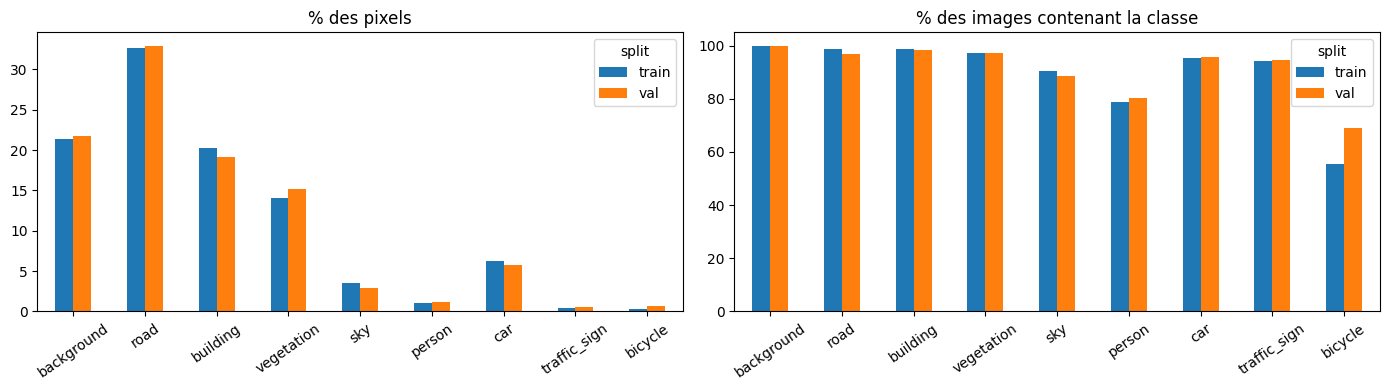

In [6]:
def class_stats(split, limit=None):
    ps = pairs[split][:limit] if limit else pairs[split]
    pixels = np.zeros(NUM_CLASSES, dtype=np.int64)
    present = np.zeros(NUM_CLASSES, dtype=np.int64)
    for _, mask_path in tqdm(ps, desc=f"masques {split}", mininterval=10):
        counts = np.bincount(remap_np(np.array(Image.open(mask_path))).ravel(), minlength=NUM_CLASSES)
        pixels += counts
        present += counts > 0
    return pd.DataFrame({
        "split": split,
        "classe": CLASS_NAMES,
        "% des pixels": 100 * pixels / pixels.sum(),
        "% des images contenant la classe": 100 * present / len(ps),
    })


stats_df = pd.concat([class_stats(s, limit=50 if QUICK_TEST else None) for s in ("train", "val")])
display(stats_df.pivot(index="classe", columns="split").round(2).loc[CLASS_NAMES])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ["% des pixels", "% des images contenant la classe"]):
    stats_df.pivot(index="classe", columns="split", values=col).loc[CLASS_NAMES].plot.bar(ax=ax, rot=35)
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

**Lecture.** Route, background et bâtiments couvrent environ 74 % des pixels, alors que personne,
panneau et vélo en couvrent moins de 2 %. Pourtant les panneaux apparaissent dans la plupart des
images : ce sont des petits objets. D'où, pour la baseline, une perte pondérée par classe ; les
transformers traitent ce problème autrement, en prédisant un masque par objet/classe.

### 2.4 Chargement des données

Pour les trois modèles :
- redimensionnement à 512×1024 (bilinéaire pour l'image, plus proche voisin pour le masque) ;
- normalisation ImageNet (moyenne/écart‑type par canal) ;
- **échantillonneur pondéré** (`WeightedRandomSampler`) : chaque image est tirée avec le poids
  maximal des classes rares qu'elle contient ;
- 4 processus de chargement (`num_workers=4`) : décoder un PNG 2048×1024 prend environ 130 ms,
  sans parallélisme le GPU attendrait.

In [7]:
print(inspect.getsource(dataloader._compute_sample_weights))
print(inspect.getsource(create_dataloaders))

sample_ds = CityscapesDataset(pairs["train"][:2], img_size=IMG_SIZE)
img, mask = sample_ds[0]
print("image :", tuple(img.shape), img.dtype, "| masque :", tuple(mask.shape), mask.dtype)

def _compute_sample_weights(dataset: CityscapesDataset) -> list:
    """
    Per-image sampling weight = the highest class_weight among the classes
    present in that mask.

    Note: in Cityscapes nearly every frame contains at least a few pixels of
    traffic_sign or bicycle (weight 3.0), so almost all images end up with the
    same weight and the sampler behaves close to uniform. Measured enrichment
    of rare-class pixels: x1.02 (a 400-image sample). Summing the weights
    instead of taking the maximum only reaches x1.08 — both look at class
    *presence*, not at how much of the frame a rare class covers. Weighting by
    rare-class *area* reaches x2.2-2.8, but that changes training behaviour and
    would require retraining, so it is deliberately not done here.

    Class imbalance is handled instead by the weighted CE + Dice loss in the
    training scripts, which penalises rare-class errors per pixel.
    """
    print(f"Computing class-balanced sample weights for {len(dat

### 2.5 Exemples

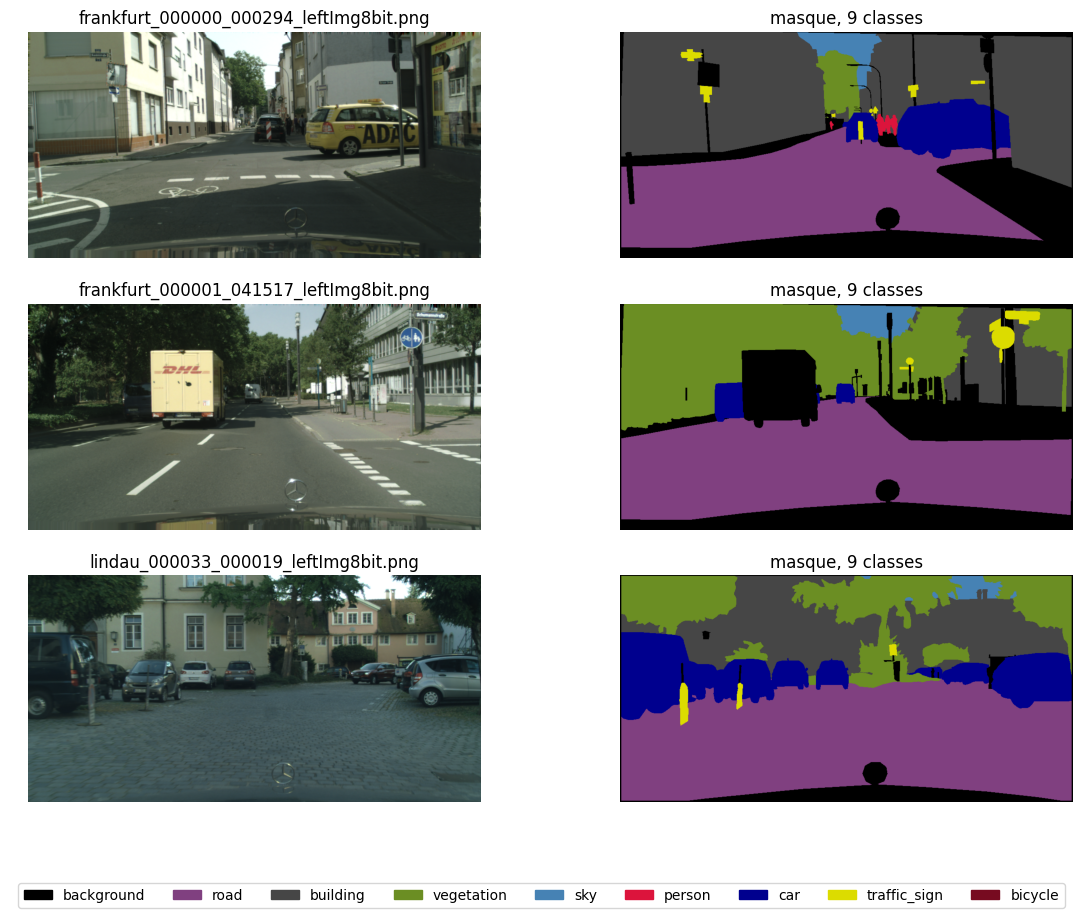

In [8]:
def colorize(labels):
    return PALETTE[labels]


fig, axes = plt.subplots(3, 2, figsize=(14, 10))
for row, (img_path, mask_path) in zip(axes, pairs["val"][::150][:3]):
    img = Image.open(img_path).convert("RGB").resize((IMG_SIZE[1], IMG_SIZE[0]), Image.BILINEAR)
    lab = remap_np(np.array(Image.open(mask_path).resize((IMG_SIZE[1], IMG_SIZE[0]), Image.NEAREST)))
    row[0].imshow(img); row[0].set_title(os.path.basename(img_path)); row[0].axis("off")
    row[1].imshow(colorize(lab)); row[1].set_title("masque, 9 classes"); row[1].axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=PALETTE[i] / 255) for i in range(NUM_CLASSES)]
fig.legend(handles, CLASS_NAMES, loc="lower center", ncol=NUM_CLASSES)
plt.show()

### 2.6 Cibles des transformers : un ensemble de masques

La baseline apprend une classe par pixel. Mask2Former et EoMT apprennent un **ensemble de
masques binaires, chacun avec une classe** : la carte d'étiquettes est donc convertie, pour chaque
image, en un masque par classe présente.

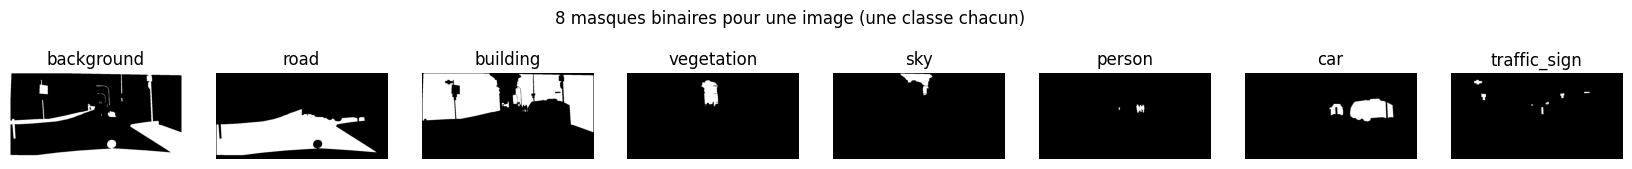

In [9]:
def to_mask_targets(masks: torch.Tensor):
    # masks : (B, H, W), classes 0..8 -> pour chaque image : masques binaires (K, H, W) + classes (K)
    mask_labels, class_labels = [], []
    for m in masks:
        classes = torch.unique(m)
        mask_labels.append((m[None] == classes[:, None, None]).float())
        class_labels.append(classes)
    return mask_labels, class_labels


_, demo_mask = CityscapesDataset(pairs["val"][:1], img_size=IMG_SIZE)[0]
demo_mask = remap_mask(demo_mask)
ml, cl = to_mask_targets(demo_mask[None])
fig, axes = plt.subplots(1, len(cl[0]), figsize=(2.6 * len(cl[0]), 2.2))
for ax, m, c in zip(np.atleast_1d(axes), ml[0], cl[0]):
    ax.imshow(m, cmap="gray"); ax.set_title(CLASS_NAMES[c]); ax.axis("off")
plt.suptitle(f"{len(cl[0])} masques binaires pour une image (une classe chacun)")
plt.show()

## 3. Outils communs

- **Métrique** : matrice de confusion cumulée sur tous les pixels, IoU par classe,
  mIoU = moyenne des IoU, précision par pixel.
- **Boucle d'entraînement** `fit()` : une époque d'entraînement puis de validation, journalisation
  MLflow, sauvegarde du **meilleur** checkpoint (mIoU de validation), **arrêt anticipé** après
  `PATIENCE` époques sans amélioration, historique enregistré en JSON.

In [10]:
class SegmentationMetrics:
    def __init__(self, num_classes=NUM_CLASSES):
        self.num_classes = num_classes
        self.confusion = np.zeros((num_classes, num_classes), dtype=np.int64)

    def update(self, preds, targets):
        preds, targets = preds.cpu().numpy().ravel(), targets.cpu().numpy().ravel()
        idx = self.num_classes * targets.astype(np.int64) + preds.astype(np.int64)
        self.confusion += np.bincount(idx, minlength=self.num_classes**2).reshape(self.num_classes, self.num_classes)

    def iou_per_class(self):
        tp = np.diag(self.confusion)
        denom = self.confusion.sum(0) + self.confusion.sum(1) - tp
        return np.where(denom > 0, tp / np.maximum(denom, 1), np.nan)

    def mean_iou(self):
        return float(np.nanmean(self.iou_per_class()))

    def pixel_accuracy(self):
        return float(np.diag(self.confusion).sum() / max(1, self.confusion.sum()))


def autocast(enabled=True):
    # bf16 sur GPU : divise la mémoire des activations par deux (GPU de 8 Go)
    return torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=enabled and DEVICE == "cuda")


class Limited:
    # Les n premiers lots d'un loader (mode test rapide uniquement)
    def __init__(self, loader, n):
        self.loader, self.n = loader, min(n, len(loader))

    def __iter__(self):
        return islice(iter(self.loader), self.n)

    def __len__(self):
        return self.n


def make_loaders(batch_size):
    train_loader, val_loader = create_dataloaders(
        IMG_ROOT, MASK_ROOT, batch_size=batch_size, balanced=True, img_size=IMG_SIZE, num_workers=NUM_WORKERS
    )
    if LIMIT:
        return Limited(train_loader, LIMIT), Limited(val_loader, LIMIT)
    return train_loader, val_loader


def fit(name, model, run_train, run_val, params, can_stop=lambda: True, extra=lambda: {}):
    # Boucle commune : run_train() / run_val() renvoient (perte moyenne, SegmentationMetrics)
    ckpt_path = os.path.join(OUT_DIR, f"{name}.pth")
    history, best, bad = [], -1.0, 0
    if USE_MLFLOW:
        import mlflow
        mlflow.set_tracking_uri(f"sqlite:///{PROJECT_ROOT}/mlflow.db")
        mlflow.set_experiment("urban-segmentation")
        run_ctx = mlflow.start_run(run_name=f"NB-{name}")
    else:
        run_ctx = contextlib.nullcontext()
    with run_ctx:
        if USE_MLFLOW:
            mlflow.log_params(params)
        for epoch in range(1, EPOCHS + 1):
            t0 = time.time()
            train_loss, train_m = run_train()
            val_loss, val_m = run_val()
            row = {
                "epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
                "train_mIoU": train_m.mean_iou(), "val_mIoU": val_m.mean_iou(),
                "val_pixel_accuracy": val_m.pixel_accuracy(), "minutes": (time.time() - t0) / 60,
                **{f"val_iou_{c}": float(v) for c, v in zip(CLASS_NAMES, val_m.iou_per_class())},
                **extra(),
            }
            history.append(row)
            if USE_MLFLOW:
                mlflow.log_metrics({k: v for k, v in row.items() if k != "epoch" and np.isfinite(v)}, step=epoch)
            improved = row["val_mIoU"] > best
            if improved:
                best, bad = row["val_mIoU"], 0
                torch.save(model.state_dict(), ckpt_path)
            elif can_stop():
                bad += 1
            print(f"[{name}] époque {epoch:2d}/{EPOCHS} | perte {train_loss:.3f}/{val_loss:.3f} | "
                  f"mIoU train {row['train_mIoU']:.4f} val {row['val_mIoU']:.4f} | {row['minutes']:.1f} min"
                  + (" | meilleur → sauvegardé" if improved else f" | sans amélioration {bad}/{PATIENCE}"))
            if bad >= PATIENCE:
                print(f"[{name}] arrêt anticipé à l'époque {epoch}")
                break
        if USE_MLFLOW:
            mlflow.log_metric("best_val_mIoU", best)
    with open(os.path.join(OUT_DIR, f"{name}_history.json"), "w") as f:
        json.dump(history, f)
    print(f"[{name}] meilleure mIoU de validation : {best:.4f} → {ckpt_path}")
    return history


def cleanup():
    # À appeler après « del » des variables d'un modèle : libère réellement la mémoire GPU
    # (sinon le modèle suivant manque de mémoire et déborde, lentement, sur la RAM)
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()


def show_history(name):
    # Modèle non ré-entraîné dans cette exécution : affiche son historique enregistré
    path = os.path.join(OUT_DIR, f"{name}_history.json")
    if not os.path.exists(path):
        print(f"[{name}] non entraîné dans cette exécution et aucun historique dans {OUT_DIR}")
        return None
    with open(path) as f:
        h = pd.DataFrame(json.load(f))
    best = h.loc[h["val_mIoU"].idxmax()]
    print(f"[{name}] entraîné lors d'une exécution précédente de ce notebook — historique enregistré :")
    print(f"  {len(h)} époques, {h['minutes'].sum() / 60:.1f} h ; meilleure mIoU de validation "
          f"{best['val_mIoU']:.4f} à l'époque {int(best['epoch'])} ; checkpoint {name}.pth")
    cols = ["epoch", "train_loss", "val_loss", "train_mIoU", "val_mIoU", "val_pixel_accuracy", "minutes"]
    display(h[cols].round(4).set_index("epoch"))
    return h

## 4. Baseline : ResNet50‑UNet

**Principe** : classification de chaque pixel par un réseau encodeur‑décodeur. L'encodeur est un
ResNet‑50 pré‑entraîné sur ImageNet ; le décodeur U‑Net remonte à la pleine résolution en
réutilisant, par des connexions de saut, les cartes de l'encodeur.

**Perte** : entropie croisée pondérée + Dice pondéré. Les poids (personne 2,5 ; panneau et vélo 3)
compensent le déséquilibre vu en 2.3.

**Optimisation** : Adam, taux d'apprentissage 1e‑5 pour l'encodeur pré‑entraîné et 1e‑4 pour le
décodeur, lots de 4 images, 20 époques.

In [11]:
class DoubleConvBN(nn.Module):
    # Conv-BN-ReLU-Conv-BN-ReLU : un bloc du décodeur
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.net(x)


class ResNet50UNet(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, pretrained=True):
        super().__init__()
        backbone = tv_models.resnet50(weights=tv_models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
        self.stem = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu)  # 64 canaux, H/2
        self.pool = backbone.maxpool                                            # H/4
        self.layer1, self.layer2 = backbone.layer1, backbone.layer2            # 256 (H/4), 512 (H/8)
        self.layer3, self.layer4 = backbone.layer3, backbone.layer4            # 1024 (H/16), 2048 (H/32)
        self.up4 = nn.ConvTranspose2d(2048, 512, 2, stride=2)
        self.dec4 = DoubleConvBN(512 + 1024, 512)
        self.up3 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec3 = DoubleConvBN(256 + 512, 256)
        self.up2 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec2 = DoubleConvBN(128 + 256, 128)
        self.up1 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec1 = DoubleConvBN(64 + 64, 32)
        self.up0 = nn.ConvTranspose2d(32, 32, 2, stride=2)                     # H/2 -> H
        self.out = nn.Conv2d(32, num_classes, 1)

    def forward(self, x):
        s0 = self.stem(x)
        s1 = self.layer1(self.pool(s0))
        s2 = self.layer2(s1)
        s3 = self.layer3(s2)
        s4 = self.layer4(s3)
        x = self.dec4(torch.cat([self.up4(s4), s3], 1))
        x = self.dec3(torch.cat([self.up3(x), s2], 1))
        x = self.dec2(torch.cat([self.up2(x), s1], 1))
        x = self.dec1(torch.cat([self.up1(x), s0], 1))
        return self.out(self.up0(x))

In [12]:
CLASS_WEIGHTS = torch.tensor([0.5, 1.0, 1.0, 1.0, 1.0, 2.5, 1.0, 3.0, 3.0])


class DiceLoss(nn.Module):
    def __init__(self, class_weights, smooth=1.0):
        super().__init__()
        self.register_buffer("weights", class_weights / class_weights.sum() * len(class_weights))
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.softmax(logits, dim=1)
        one_hot = torch.zeros_like(probs).scatter_(1, targets.unsqueeze(1), 1.0)
        inter = (probs * one_hot).sum(dim=(0, 2, 3))
        denom = (probs + one_hot).sum(dim=(0, 2, 3))
        dice = (2 * inter + self.smooth) / (denom + self.smooth)
        return 1 - (dice * self.weights).sum() / self.weights.sum()


class CombinedLoss(nn.Module):
    def __init__(self, class_weights):
        super().__init__()
        self.ce = nn.CrossEntropyLoss(weight=class_weights)
        self.dice = DiceLoss(class_weights)

    def forward(self, logits, targets):
        return self.ce(logits, targets) + self.dice(logits, targets)


def baseline_train_epoch(model, loader, optimizer, criterion):
    model.train()
    total, metrics = 0.0, SegmentationMetrics()
    for imgs, masks in tqdm(loader, desc="train", mininterval=30, leave=False):
        imgs, masks = imgs.to(DEVICE), remap_mask(masks).to(DEVICE)
        optimizer.zero_grad()
        logits = model(imgs)
        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()
        total += loss.item()
        metrics.update(logits.argmax(1), masks)
    return total / len(loader), metrics


@torch.no_grad()
def baseline_val_epoch(model, loader, criterion):
    model.eval()
    total, metrics = 0.0, SegmentationMetrics()
    for imgs, masks in tqdm(loader, desc="val", mininterval=30, leave=False):
        imgs, masks = imgs.to(DEVICE), remap_mask(masks).to(DEVICE)
        logits = model(imgs)
        total += criterion(logits, masks).item()
        metrics.update(logits.argmax(1), masks)
    return total / len(loader), metrics

In [13]:
if TRAIN["ResNet50-UNet"]:
    set_seed()
    train_loader, val_loader = make_loaders(batch_size=4)
    model = ResNet50UNet(pretrained=True).to(DEVICE)
    criterion = CombinedLoss(CLASS_WEIGHTS).to(DEVICE)
    encoder = [p for m in (model.stem, model.layer1, model.layer2, model.layer3, model.layer4) for p in m.parameters()]
    enc_ids = {id(p) for p in encoder}
    decoder = [p for p in model.parameters() if id(p) not in enc_ids]
    optimizer = torch.optim.Adam([{"params": encoder, "lr": 1e-5}, {"params": decoder, "lr": 1e-4}])
    history_baseline = fit(
        "ResNet50-UNet", model,
        lambda: baseline_train_epoch(model, train_loader, optimizer, criterion),
        lambda: baseline_val_epoch(model, val_loader, criterion),
        params={"architecture": "ResNet50-UNet", "batch_size": 4, "lr_encoder": 1e-5, "lr_decoder": 1e-4,
                "optimizer": "Adam", "loss": "CE+Dice (pondérées)", "epochs": EPOCHS, "img_size": "512x1024"},
    )
    del model, optimizer, criterion, encoder, decoder, enc_ids, train_loader, val_loader
    cleanup()
else:
    history_baseline = show_history("ResNet50-UNet")

[ResNet50-UNet] entraîné lors d'une exécution précédente de ce notebook — historique enregistré :
  20 époques, 2.5 h ; meilleure mIoU de validation 0.8152 à l'époque 20 ; checkpoint ResNet50-UNet.pth


,train_loss,val_loss,train_mIoU,val_mIoU,val_pixel_accuracy,minutes
epoch,,,,,,
1,1.9607,1.4810,0.2477,0.3154,0.6917,8.0118
2,1.2661,1.1756,0.4428,0.5304,0.8870,7.2752
3,1.0985,1.1076,0.5423,0.4971,0.8667,7.4345
4,0.9289,0.9565,0.5502,0.5425,0.8959,7.6804
5,0.7857,0.8200,0.6165,0.6397,0.9013,7.6726
6,0.6323,0.6943,0.7235,0.6897,0.9119,7.6972
7,0.4740,0.6004,0.7912,0.7931,0.9198,7.7026
8,0.3817,0.5358,0.8476,0.7983,0.9194,7.6514
9,0.3127,0.5087,0.8581,0.8046,0.9226,7.7073


## 5. Nouvelle méthode (1) : Mask2Former

**Principe** (Cheng et al., 2022) : au lieu d'une classe par pixel, le modèle prédit **100 paires
(masque, classe)**. Un décodeur transformer affine 100 « requêtes » ; avec l'*attention masquée*,
chaque requête ne regarde que la zone de son masque courant. À l'entraînement, prédictions et
masques réels sont appariés par l'**algorithme hongrois**, puis la perte combine entropie croisée
sur les classes, BCE et Dice sur les masques.

**Point de départ** : Mask2Former Swin‑Tiny pré‑entraîné sur ADE20K (n'a jamais vu Cityscapes) ;
seule la tête de classification est remplacée (150 → 9 classes).

**Recette** (celle de l'article) : AdamW (décroissance des poids 0,05), taux 1e‑4 (1e‑5 pour le
backbone), *warm‑up* linéaire puis décroissance polynomiale (0,9), écrêtage du gradient à 0,01.
Lots de 2 avec **accumulation de gradient sur 2 lots** : lot effectif de 4, comme la baseline
(un lot de 4 ne tient pas dans 8 Go).

**Prédiction sémantique** : score d'une classe en un pixel = somme sur les requêtes de
(probabilité de la classe × probabilité du masque).

In [14]:
from transformers import Mask2FormerForUniversalSegmentation

M2F_PRETRAINED = "facebook/mask2former-swin-tiny-ade-semantic"
ID2LABEL = dict(enumerate(CLASS_NAMES))
LABEL2ID = {n: i for i, n in enumerate(CLASS_NAMES)}


def build_mask2former():
    return Mask2FormerForUniversalSegmentation.from_pretrained(
        M2F_PRETRAINED, id2label=ID2LABEL, label2id=LABEL2ID,
        ignore_mismatched_sizes=True,  # tête de classification : 151 -> 10 sorties (9 classes + « aucun objet »)
    )


def semantic_logits(outputs, size):
    # (B, Q, C+1) et (B, Q, h, w) -> scores (B, C, H, W) ; la dernière classe (« aucun objet ») est ignorée
    class_probs = outputs.class_queries_logits.float().softmax(-1)[..., :-1]
    mask_probs = F.interpolate(outputs.masks_queries_logits.float().sigmoid(), size=size, mode="bilinear", align_corners=False)
    return torch.einsum("bqc,bqhw->bchw", class_probs, mask_probs)


def poly_with_warmup(total_steps, warmup_steps, power=0.9):
    # multiplicateur du taux : montée linéaire, puis décroissance polynomiale jusqu'à 0
    def factor(step):
        if step < warmup_steps:
            return 0.001 + 0.999 * step / warmup_steps
        return max(0.0, 1 - (step - warmup_steps) / max(1, total_steps - warmup_steps)) ** power
    return factor


def mc_train_epoch(model, loader, optimizer, scheduler, accum_steps=2, clip=0.01, on_step=None):
    # Entraînement « classification de masques » (Mask2Former et EoMT)
    model.train()
    total, metrics = 0.0, SegmentationMetrics()
    optimizer.zero_grad()
    for i, (imgs, masks) in enumerate(tqdm(loader, desc="train", mininterval=30, leave=False), start=1):
        imgs, masks = imgs.to(DEVICE), remap_mask(masks).to(DEVICE)
        mask_labels, class_labels = to_mask_targets(masks)
        with autocast():
            outputs = model(pixel_values=imgs, mask_labels=mask_labels, class_labels=class_labels)
        (outputs.loss / accum_steps).backward()
        if i % accum_steps == 0 or i == len(loader):
            torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()
            if on_step:
                on_step()
        total += outputs.loss.item()
        with torch.no_grad():
            metrics.update(semantic_logits(outputs, masks.shape[-2:]).argmax(1), masks)
    return total / len(loader), metrics


@torch.no_grad()
def mc_val_epoch(model, loader):
    model.eval()
    total, metrics = 0.0, SegmentationMetrics()
    for imgs, masks in tqdm(loader, desc="val", mininterval=30, leave=False):
        imgs, masks = imgs.to(DEVICE), remap_mask(masks).to(DEVICE)
        mask_labels, class_labels = to_mask_targets(masks)
        with autocast():
            outputs = model(pixel_values=imgs, mask_labels=mask_labels, class_labels=class_labels)
        total += outputs.loss.item()
        metrics.update(semantic_logits(outputs, masks.shape[-2:]).argmax(1), masks)
    return total / len(loader), metrics

In [ ]:
if TRAIN["Mask2Former-SwinT"]:
    set_seed()
    train_loader, val_loader = make_loaders(batch_size=2)
    model = build_mask2former().to(DEVICE)
    backbone = list(model.model.pixel_level_module.encoder.parameters())
    bb_ids = {id(p) for p in backbone}
    rest = [p for p in model.parameters() if id(p) not in bb_ids]
    optimizer = torch.optim.AdamW([{"params": backbone, "lr": 1e-5}, {"params": rest, "lr": 1e-4}], weight_decay=0.05)
    total_steps = math.ceil(len(train_loader) / 2) * EPOCHS
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, poly_with_warmup(total_steps, warmup_steps=250))
    history_m2f = fit(
        "Mask2Former-SwinT", model,
        lambda: mc_train_epoch(model, train_loader, optimizer, scheduler, accum_steps=2),
        lambda: mc_val_epoch(model, val_loader),
        params={"architecture": "Mask2Former-SwinT", "pretrained": M2F_PRETRAINED, "batch_size": 2,
                "accum_steps": 2, "lr": 1e-4, "lr_backbone": 1e-5, "optimizer": "AdamW(wd=0.05)",
                "lr_schedule": "warm-up 250 + poly(0.9)", "precision": "bf16", "epochs": EPOCHS},
    )
    del model, optimizer, scheduler, backbone, bb_ids, rest, train_loader, val_loader
    cleanup()
else:
    history_m2f = show_history("Mask2Former-SwinT")

## 6. Nouvelle méthode (2) : EoMT

**Principe** (Kerssies et al., 2025) : même sortie que Mask2Former (masques + classes, même perte)
mais **sans décodeur** : 200 requêtes sont ajoutées aux patchs de l'image dans les **3 derniers
blocs d'un ViT simple** (ViT‑B, pré‑entraîné DINOv2). Le modèle est plus simple et, sur GPU,
nettement plus rapide.

**Adaptations nécessaires**
- **Résolution** : le modèle pré‑entraîné attend des images carrées 640×640 (grille de 40×40
  positions). Les *position embeddings* sont interpolées (bicubique) vers la grille 32×64 de nos
  images 512×1024.
- **Point de départ** : EoMT‑B pré‑entraîné sur COCO panoptique (n'a jamais vu Cityscapes), tête
  remplacée (133 → 9 classes).

**Recette** (code officiel EoMT, mise à l'échelle de notre nombre de pas) :
- **taux d'apprentissage par couche** (*layer‑wise decay* 0,8) : la couche *l* du ViT apprend au
  taux 1e‑4 × 0,8^(11−l) ;
- ***warm‑up* en deux temps** : les têtes d'abord (ViT gelé), puis le ViT ; ensuite décroissance
  polynomiale ;
- ***mask annealing*** : l'attention masquée est utilisée au début puis supprimée bloc par bloc
  (probabilité 1 → 0), pour qu'à l'inférence le modèle fonctionne **sans masque** (c'est ce qui le
  rend rapide). La validation est faite sans masque, comme en production ; l'arrêt anticipé est
  suspendu pendant cette transition.

In [ ]:
from transformers import EomtForUniversalSegmentation

EOMT_PRETRAINED = "tue-mps/coco_panoptic_eomt_base_640_2x"


def resize_position_embeddings(model, grid):
    # grille carrée 40x40 du modèle pré-entraîné -> grille 32x64 (512x1024 / patchs de 16)
    emb = model.embeddings
    old = emb.position_embeddings.weight.data
    n, dim = old.shape
    side = int(math.sqrt(n))
    old = old.reshape(1, side, side, dim).permute(0, 3, 1, 2)
    new = F.interpolate(old.float(), size=grid, mode="bicubic", align_corners=False).permute(0, 2, 3, 1).reshape(-1, dim)
    emb.position_embeddings = nn.Embedding(new.shape[0], dim)
    emb.position_embeddings.weight.data.copy_(new)
    emb.register_buffer("position_ids", torch.arange(new.shape[0]).unsqueeze(0), persistent=False)
    model.grid_size = grid


def build_eomt():
    model = EomtForUniversalSegmentation.from_pretrained(
        EOMT_PRETRAINED, id2label=ID2LABEL, label2id=LABEL2ID,
        ignore_mismatched_sizes=True,  # tête : 134 -> 10 sorties
    )
    patch = model.config.patch_size
    resize_position_embeddings(model, (IMG_SIZE[0] // patch, IMG_SIZE[1] // patch))
    return model


def eomt_param_groups(model, lr=1e-4, llrd=0.8):
    # couche l du ViT : lr * llrd**(L-1-l) ; embeddings : taux le plus bas ; norme finale et têtes : lr
    n_layers = model.config.num_hidden_layers
    backbone, other = {}, []
    for name, p in model.named_parameters():
        if name.startswith("embeddings."):
            depth = 0
        elif name.startswith("layers."):
            depth = int(name.split(".")[1])
        elif name.startswith("layernorm."):
            depth = n_layers - 1
        else:
            other.append(p)
            continue
        backbone.setdefault(depth, []).append(p)
    vit = [{"params": ps, "lr": lr * llrd ** (n_layers - 1 - d)} for d, ps in sorted(backbone.items())]
    return vit, [{"params": other, "lr": lr}]


def two_stage_warmup_poly(total_steps, head_warmup, vit_warmup, power=0.9):
    def head(step):
        if step < head_warmup:
            return step / head_warmup
        return max(0.0, 1 - (step - head_warmup) / max(1, total_steps - head_warmup)) ** power

    def vit(step):
        if step < head_warmup:
            return 0.0  # ViT gelé pendant le warm-up des têtes
        if step < head_warmup + vit_warmup:
            return (step - head_warmup) / vit_warmup
        return max(0.0, 1 - (step - head_warmup - vit_warmup) / max(1, total_steps - head_warmup - vit_warmup)) ** power

    return vit, head


class MaskAnnealer:
    # Probabilité de garder l'attention masquée dans chacun des derniers blocs : 1 -> 0, bloc par bloc.
    # L'entraînement est découpé en (blocs + 2) parts égales : le bloc i décroît pendant la part i+1,
    # la dernière part est sans masque (proportions de la configuration Cityscapes officielle).
    def __init__(self, model, total_steps, power=0.9):
        self.model, self.power, self.step_count = model, power, 0
        n = model.config.num_blocks
        unit = total_steps // (n + 2)
        self.starts = [(i + 1) * unit for i in range(n)]
        self.ends = [(i + 2) * unit for i in range(n)]
        self._apply()

    def _prob(self, start, end):
        if self.step_count < start:
            return 1.0
        if self.step_count >= end:
            return 0.0
        return (1 - (self.step_count - start) / (end - start)) ** self.power

    def _apply(self):
        for i, (s, e) in enumerate(zip(self.starts, self.ends)):
            self.model.attn_mask_probs[i] = self._prob(s, e)

    def step(self):
        self.step_count += 1
        self._apply()

    @property
    def done(self):
        return self.step_count >= self.ends[-1]


def eomt_val_epoch(model, loader):
    # validation sans attention masquée (comme en production), puis rétablissement
    saved = model.attn_mask_probs.clone()
    model.attn_mask_probs.zero_()
    try:
        return mc_val_epoch(model, loader)
    finally:
        model.attn_mask_probs.copy_(saved)

In [ ]:
if TRAIN["EoMT-B"]:
    set_seed()
    train_loader, val_loader = make_loaders(batch_size=2)
    model = build_eomt().to(DEVICE)
    total_steps = math.ceil(len(train_loader) / 2) * EPOCHS
    vit_groups, head_groups = eomt_param_groups(model)
    optimizer = torch.optim.AdamW(vit_groups + head_groups, weight_decay=0.05)
    # warm-up : 500 et 1 000 pas sur ~19 900 dans la configuration officielle -> mêmes proportions ici
    head_warmup, vit_warmup = round(total_steps * 0.025), round(total_steps * 0.05)
    vit_f, head_f = two_stage_warmup_poly(total_steps, max(1, head_warmup), max(1, vit_warmup))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, [vit_f] * len(vit_groups) + [head_f] * len(head_groups))
    annealer = MaskAnnealer(model, total_steps)
    print("mask annealing : début", annealer.starts, "fin", annealer.ends, "(pas d'optimisation)")
    history_eomt = fit(
        "EoMT-B", model,
        lambda: mc_train_epoch(model, train_loader, optimizer, scheduler, accum_steps=2, on_step=annealer.step),
        lambda: eomt_val_epoch(model, val_loader),
        params={"architecture": "EoMT-B", "pretrained": EOMT_PRETRAINED, "batch_size": 2, "accum_steps": 2,
                "lr": 1e-4, "llrd": 0.8, "lr_schedule": f"two-stage warm-up ({head_warmup}, {vit_warmup}) + poly(0.9)",
                "mask_annealing": f"{annealer.starts} -> {annealer.ends}", "precision": "bf16",
                "val_mode": "sans masque", "epochs": EPOCHS},
        can_stop=lambda: annealer.done,
        extra=lambda: {f"attn_mask_prob_{i}": float(p) for i, p in enumerate(model.attn_mask_probs)},
    )
    del model, optimizer, scheduler, annealer, vit_groups, head_groups, train_loader, val_loader
    cleanup()
else:
    history_eomt = show_history("EoMT-B")

## 7. Résultats et comparaison

### 7.1 Courbes d'apprentissage

In [ ]:
MODELS = ["ResNet50-UNet", "Mask2Former-SwinT", "EoMT-B"]
COLORS = {"ResNet50-UNet": "#2a78d6", "Mask2Former-SwinT": "#eb6834", "EoMT-B": "#1baf7a"}

histories = {}
for name in MODELS:
    path = os.path.join(OUT_DIR, f"{name}_history.json")
    if os.path.exists(path):
        with open(path) as f:
            histories[name] = pd.DataFrame(json.load(f))
print("historiques disponibles :", list(histories))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name, h in histories.items():
    axes[0].plot(h["epoch"], h["val_mIoU"], marker="o", ms=3, color=COLORS[name], label=name)
    axes[1].plot(h["epoch"], h["train_mIoU"] - h["val_mIoU"], marker="o", ms=3, color=COLORS[name], label=name)
axes[0].set_title("mIoU de validation par époque"); axes[0].set_xlabel("époque")
axes[1].set_title("écart train − validation (sur-apprentissage)"); axes[1].set_xlabel("époque")
axes[1].axhline(0, color="gray", lw=1)
for ax in axes:
    ax.grid(alpha=0.3); ax.legend()
plt.show()

pd.DataFrame({n: {"meilleure époque": int(h.loc[h["val_mIoU"].idxmax(), "epoch"]),
                  "meilleure mIoU val": h["val_mIoU"].max(),
                  "durée totale (h)": h["minutes"].sum() / 60} for n, h in histories.items()}).T.round(4)

### 7.2 Ré‑évaluation des meilleurs checkpoints

Les trois meilleurs checkpoints sont rechargés et évalués **par le même code** sur les 500 images
de validation, dans la précision de leur entraînement (baseline en fp32, transformers en bf16 ;
EoMT sans masque). On garde une matrice de confusion **par image**, pour le bootstrap.

In [ ]:
def load_trained(name):
    path = os.path.join(OUT_DIR, f"{name}.pth")
    if not os.path.exists(path):
        return None
    if name == "ResNet50-UNet":
        model = ResNet50UNet(pretrained=False)
    elif name == "Mask2Former-SwinT":
        model = build_mask2former()
    else:
        model = build_eomt()
    model.load_state_dict(torch.load(path, map_location="cpu"))
    if name == "EoMT-B":
        model.attn_mask_probs.zero_()
    return model.to(DEVICE).eval()


def predict(name, model, imgs, bf16):
    with autocast(bf16):
        if name == "ResNet50-UNet":
            return model(imgs).argmax(1)
        return semantic_logits(model(pixel_values=imgs), imgs.shape[-2:]).argmax(1)


def confusion(pred, gt):
    return torch.bincount((gt.flatten() * NUM_CLASSES + pred.flatten()), minlength=NUM_CLASSES**2).reshape(NUM_CLASSES, NUM_CLASSES).cpu().numpy()


def scores(conf):
    tp = np.diag(conf).astype(float)
    denom = conf.sum(0) + conf.sum(1) - tp
    iou = np.where(denom > 0, tp / np.maximum(denom, 1), np.nan)
    return float(np.nanmean(iou)), iou, float(tp.sum() / conf.sum())


val_pairs = pairs["val"][:8] if QUICK_TEST else pairs["val"]
val_eval_loader = DataLoader(CityscapesDataset(val_pairs, img_size=IMG_SIZE), batch_size=2, shuffle=False, num_workers=NUM_WORKERS)

confs, rows = {}, []
for name in MODELS:
    model = load_trained(name)
    if model is None:
        print(f"{name} : pas de checkpoint dans {OUT_DIR}, ignoré")
        continue
    bf16 = name != "ResNet50-UNet"
    per_image = []
    with torch.no_grad():
        for imgs, masks in tqdm(val_eval_loader, desc=name, mininterval=30, leave=False):
            imgs, masks = imgs.to(DEVICE), remap_mask(masks).to(DEVICE)
            for p, g in zip(predict(name, model, imgs, bf16), masks):
                per_image.append(confusion(p, g))
    confs[name] = np.stack(per_image)
    miou, iou, pa = scores(confs[name].sum(0))
    # temps d'inférence d'une image (GPU, bf16)
    x = torch.randn(1, 3, *IMG_SIZE, device=DEVICE)
    with torch.no_grad():
        for _ in range(3):
            predict(name, model, x, True)
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(10):
            predict(name, model, x, True)
        if DEVICE == "cuda":
            torch.cuda.synchronize()
    rows.append({"modèle": name, "mIoU val": miou, "précision pixel": pa,
                 "paramètres (M)": sum(p.numel() for p in model.parameters()) / 1e6,
                 "inférence bf16 (ms)": (time.perf_counter() - t0) / 10 * 1000,
                 **{c: v for c, v in zip(CLASS_NAMES, iou)}})
    del model
    cleanup()

results_df = pd.DataFrame(rows).set_index("modèle")
display(results_df[["mIoU val", "précision pixel", "paramètres (M)", "inférence bf16 (ms)"]].round(4))
display(results_df[CLASS_NAMES].T.round(4))

### 7.3 L'écart est‑il significatif ? Bootstrap apparié

On ré‑échantillonne 2 000 fois les images de validation (avec remise, les mêmes pour les deux
modèles) et on recalcule la différence de mIoU. L'intervalle à 95 % qui exclut 0 indique une
différence robuste au choix des images. Il ne couvre pas la variabilité due à un nouvel
entraînement (une seule exécution par modèle).

In [ ]:
def paired_bootstrap(conf_a, conf_b, n_resamples=2000, seed=0):
    rng = np.random.default_rng(seed)
    n = len(conf_a)
    deltas = np.empty(n_resamples)
    for r in range(n_resamples):
        idx = rng.integers(0, n, n)
        deltas[r] = scores(conf_b[idx].sum(0))[0] - scores(conf_a[idx].sum(0))[0]
    return deltas


n_boot = 50 if QUICK_TEST else 2000
boot_rows = []
for a, b in [("ResNet50-UNet", "Mask2Former-SwinT"), ("ResNet50-UNet", "EoMT-B"), ("Mask2Former-SwinT", "EoMT-B")]:
    if a in confs and b in confs:
        d = paired_bootstrap(confs[a], confs[b], n_boot)
        delta = scores(confs[b].sum(0))[0] - scores(confs[a].sum(0))[0]
        lo, hi = np.percentile(d, [2.5, 97.5])
        boot_rows.append({"comparaison": f"{b} − {a}", "Δ mIoU": delta, "IC 95 % bas": lo, "IC 95 % haut": hi,
                          "significatif": "oui" if lo > 0 or hi < 0 else "non"})
pd.DataFrame(boot_rows).round(4)

### 7.4 Exemples de prédictions

In [ ]:
models_loaded = {n: load_trained(n) for n in confs}
examples = val_pairs[:: max(1, len(val_pairs) // 3)][:3]
fig, axes = plt.subplots(len(examples), 2 + len(models_loaded), figsize=(4.2 * (2 + len(models_loaded)), 2.6 * len(examples)))
axes = np.atleast_2d(axes)
for row, pair in zip(axes, examples):
    img_t, mask_t = CityscapesDataset([pair], img_size=IMG_SIZE)[0]
    gt = remap_mask(mask_t).numpy()
    row[0].imshow(Image.open(pair[0]).convert("RGB").resize((IMG_SIZE[1], IMG_SIZE[0]))); row[0].set_title("image")
    row[1].imshow(colorize(gt)); row[1].set_title("vérité terrain")
    for ax, (name, model) in zip(row[2:], models_loaded.items()):
        with torch.no_grad():
            pred = predict(name, model, img_t[None].to(DEVICE), name != "ResNet50-UNet")[0].cpu().numpy()
        miou = scores(confusion(torch.tensor(pred), torch.tensor(gt)))[0]
        ax.imshow(colorize(pred)); ax.set_title(f"{name}\nmIoU image {miou:.3f}")
    for ax in row:
        ax.axis("off")
plt.tight_layout()
plt.show()
del models_loaded
cleanup()

### 7.5 Comparaison avec les résultats de référence

Les résultats présentés dans le rapport et le dashboard proviennent des entraînements de référence
(scripts `src/training_*.py`, même code). Un nouvel entraînement n'est pas identique au bit près
(initialisation de la tête, ordre des images, calcul GPU non déterministe) : de petits écarts de
mIoU sont attendus. Ils donnent un ordre de grandeur de la variabilité d'un entraînement à l'autre.

In [ ]:
ref_path = os.path.join(PROJECT_ROOT, "results", "poc_comparison.json")
if os.path.exists(ref_path) and len(results_df):
    with open(ref_path, encoding="utf-8") as f:
        ref = json.load(f)["models"]
    cmp = pd.DataFrame({
        "mIoU (ce notebook)": results_df["mIoU val"],
        "mIoU (référence)": pd.Series({n: ref[n]["mIoU"] for n in ref}),
    })
    cmp["écart"] = cmp["mIoU (ce notebook)"] - cmp["mIoU (référence)"]
    display(cmp.round(4))
else:
    print("Résultats de référence non trouvés (results/poc_comparison.json).")

## 8. Conclusion

- **Préparation des données** : Cityscapes ramené à 9 classes en 512×1024, avec un fort
  déséquilibre (moins de 2 % des pixels pour personne, panneau et vélo), traité par un
  échantillonneur pondéré pour tous les modèles et une perte pondérée pour la baseline.
- **Comparaison équitable** : mêmes données, même résolution, même métrique, même budget
  (20 époques, lot effectif de 4, arrêt anticipé) ; chaque modèle garde la recette de son article.
- **Résultats** (section 7, à lire avec les chiffres obtenus ci‑dessus) : dans les entraînements de
  référence, Mask2Former et EoMT dépassent la baseline d'environ +0,026 à +0,027 de mIoU, de
  façon significative (bootstrap), surtout sur les petites classes ; EoMT égale Mask2Former en
  précision avec une architecture sans décodeur, environ 2,4× plus rapide sur GPU en bf16.
- **Limites** : une seule exécution par modèle ; la validation sert à la fois au choix de l'époque
  et au rapport ; points de départ pré‑entraînés différents (ImageNet, ADE20K, COCO) ; pas
  d'augmentation de données (les deux transformers montrent un sur‑apprentissage modéré).